# History of Loto Numbers in Romania

In [ ]:
import pandas as pd

loto_numbers = pd.read_csv("loto_numbers.txt")

In [2]:
# ne uitam la primele 5 extrageri
loto_numbers.head(5)

,Anul,Luna,Ziua,Nr.1,Nr.2,Nr.3,Nr.4,Nr.5,Nr.6
0,1993,8,8,38,17,47,25,30,37
1,1993,8,15,6,7,30,17,2,42
2,1993,8,22,44,20,17,3,38,45
3,1993,8,29,42,30,36,5,4,6
4,1993,9,5,5,14,7,49,35,19


In [3]:
len(loto_numbers)

1760

In [4]:
small_test = loto_numbers[:5]
small_test

,Anul,Luna,Ziua,Nr.1,Nr.2,Nr.3,Nr.4,Nr.5,Nr.6
0,1993,8,8,38,17,47,25,30,37
1,1993,8,15,6,7,30,17,2,42
2,1993,8,22,44,20,17,3,38,45
3,1993,8,29,42,30,36,5,4,6
4,1993,9,5,5,14,7,49,35,19


In [5]:
year = list(loto_numbers['Anul'].values)
month = list(loto_numbers['Luna'].values)
day = list(loto_numbers['Ziua'].values)

extraction_date = pd.DataFrame({'year': year,
                   'month': month,
                   'day': day})
extraction_date = pd.to_datetime(extraction_date)
extraction_date = pd.DataFrame(extraction_date)

extraction_date.columns = ['extraction_date']
extraction_date.head(2)

,extraction_date
0,1993-08-08
1,1993-08-15


In [6]:
loto_numbers.__delitem__('Anul')
loto_numbers.__delitem__('Luna')
loto_numbers.__delitem__('Ziua')
loto_numbers.head(2)

,Nr.1,Nr.2,Nr.3,Nr.4,Nr.5,Nr.6
0,38,17,47,25,30,37
1,6,7,30,17,2,42


In [7]:
# get one row from the DataFrame
row = loto_numbers.iloc[0]
print(row)
print('\n')
print('Nr.1: ',row['Nr.1'])

Nr.1    38
Nr.2    17
Nr.3    47
Nr.4    25
Nr.5    30
Nr.6    37
Name: 0, dtype: int64


Nr.1:  38


In [8]:
# build a dictionary with loto numbers occurrences
occurrences = {key:[] for key in range(1,50)}
print(occurrences)

{1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: [], 10: [], 11: [], 12: [], 13: [], 14: [], 15: [], 16: [], 17: [], 18: [], 19: [], 20: [], 21: [], 22: [], 23: [], 24: [], 25: [], 26: [], 27: [], 28: [], 29: [], 30: [], 31: [], 32: [], 33: [], 34: [], 35: [], 36: [], 37: [], 38: [], 39: [], 40: [], 41: [], 42: [], 43: [], 44: [], 45: [], 46: [], 47: [], 48: [], 49: []}


In [9]:
# get column names: Nr.1, Nr.2, etc.
column_names = list(loto_numbers.columns.values)
print(column_names)

['Nr.1', 'Nr.2', 'Nr.3', 'Nr.4', 'Nr.5', 'Nr.6']


In [10]:
for i in range(loto_numbers.shape[0]):
    row = loto_numbers.iloc[i]
    
    numbers_in_row = []
    
    for column_name in column_names:
        number = row[column_name]
        
        numbers_in_row.append(number)
        
    for j in range(1,50):
        if j in numbers_in_row:
            occurrences[j].append(1)
        else:
            occurrences[j].append(0)

In [11]:
# marimea este aceeasi
print(len(occurrences[38]))
print(loto_numbers.shape[0])

1760
1760


In [12]:
print(occurrences[38][:1])
print(occurrences[17][:1])
print(occurrences[47][:1])
print(occurrences[25][:1])
print(occurrences[30][:1])
print(occurrences[37][:1])
# test
print('\n test: ', occurrences[1][:1])

[1]
[1]
[1]
[1]
[1]
[1]

 test:  [0]


In [13]:
occurrences_df = pd.DataFrame(occurrences)
print(occurrences_df.head(2))

column_names = list(occurrences_df.columns.values)
print(column_names)

print('\n nr. randuri: ', occurrences_df.shape[0])

   1   2   3   4   5   6   7   8   9   10 ...  40  41  42  43  44  45  46  47  \
0   0   0   0   0   0   0   0   0   0   0 ...   0   0   0   0   0   0   0   1   
1   0   1   0   0   0   1   1   0   0   0 ...   0   0   1   0   0   0   0   0   

   48  49  
0   0   0  
1   0   0  

[2 rows x 49 columns]
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]

 nr. randuri:  1760


In [14]:
count = 0
for i in range(occurrences_df.shape[0]):
    if count == 0:
        pass
    else:
        occurrences_df.iloc[i] = occurrences_df.iloc[i] + occurrences_df.iloc[i-1]
    count += 1

In [15]:
# tail gets the last rows
occurrences_df.tail(3)

,1,2,3,4,5,6,7,8,9,10,...,40,41,42,43,44,45,46,47,48,49
1757,213,234,213,234,248,229,204,201,236,208,...,174,217,189,226,219,218,226,200,221,195
1758,213,234,213,234,248,229,205,201,236,208,...,174,217,189,226,219,218,226,200,221,195
1759,213,234,213,235,248,229,205,201,236,208,...,174,217,189,227,219,219,226,200,221,195


In [16]:
# verification using Counter
loto_numbers = pd.read_csv("loto_numbers.txt")
loto_numbers.__delitem__('Anul')
loto_numbers.__delitem__('Luna')
loto_numbers.__delitem__('Ziua')
loto_array = loto_numbers.values

In [17]:
import numpy as np

loto_array = np.concatenate(loto_array)
loto_array

array([38, 17, 47, ..., 14, 18,  4])

In [18]:
from collections import Counter

unique_values = Counter(loto_array)
print(unique_values[1])
print(unique_values[2])
print(unique_values[49])

213
234
195


In [19]:
occurrences_df = occurrences_df.join(extraction_date)
occurrences_df.tail(2)

,1,2,3,4,5,6,7,8,9,10,...,41,42,43,44,45,46,47,48,49,extraction_date
1758,213,234,213,234,248,229,205,201,236,208,...,217,189,226,219,218,226,200,221,195,2018-08-30
1759,213,234,213,235,248,229,205,201,236,208,...,217,189,227,219,219,226,200,221,195,2018-09-02


In [20]:
# see the six most common numbers
last_row_number = len(occurrences_df) - 1
last_row = occurrences_df.iloc[last_row_number]

a = last_row.to_dict()
a.pop('extraction_date', None)

print(type(a))

# get max from dictionary
max(a, key=a.get)


<class 'dict'>


5

In [21]:
import operator
sorted_d = sorted(a.items(), key=operator.itemgetter(1), reverse=True)
print(sorted_d)

[(5, 248), (36, 242), (9, 236), (4, 235), (17, 235), (2, 234), (6, 229), (23, 229), (13, 228), (43, 227), (12, 226), (25, 226), (46, 226), (15, 225), (33, 223), (48, 221), (16, 220), (32, 220), (27, 219), (34, 219), (38, 219), (44, 219), (45, 219), (29, 218), (41, 217), (18, 215), (37, 215), (20, 214), (1, 213), (3, 213), (11, 213), (14, 212), (28, 212), (24, 210), (30, 210), (19, 209), (10, 208), (22, 206), (7, 205), (39, 205), (21, 203), (8, 201), (26, 201), (47, 200), (35, 195), (49, 195), (42, 189), (31, 182), (40, 174)]


In [22]:
occurrences_df = pd.DataFrame(occurrences_df).set_index('extraction_date')
occurrences_df.tail(2)

,1,2,3,4,5,6,7,8,9,10,...,40,41,42,43,44,45,46,47,48,49
extraction_date,,,,,,,,,,,,,,,,,,,,,
2018-08-30,213,234,213,234,248,229,205,201,236,208,...,174,217,189,226,219,218,226,200,221,195
2018-09-02,213,234,213,235,248,229,205,201,236,208,...,174,217,189,227,219,219,226,200,221,195


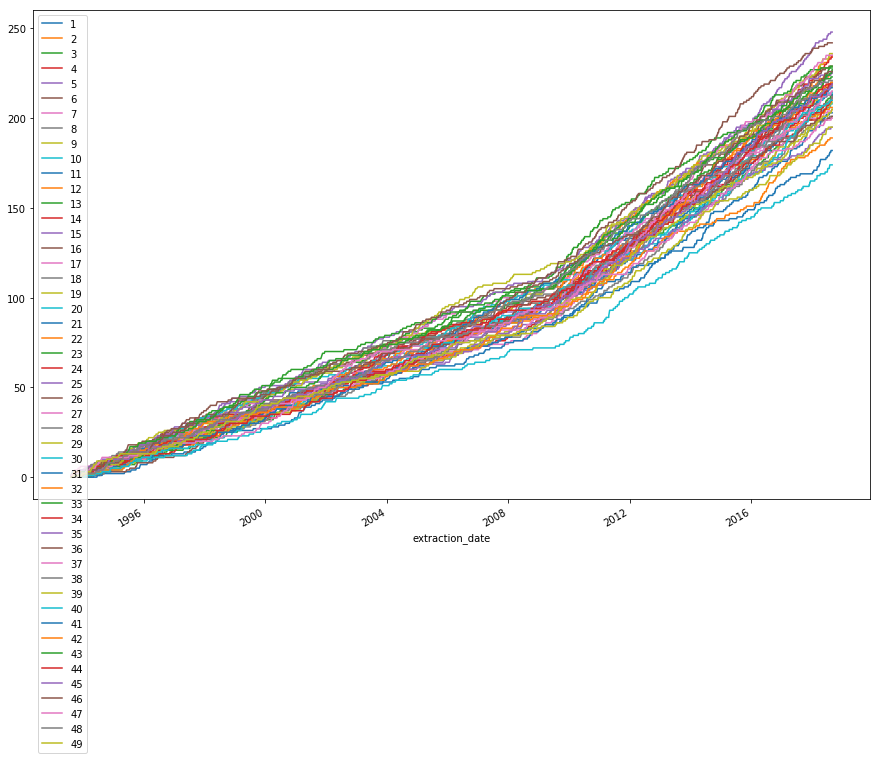

In [23]:
%matplotlib inline

occurrences_df.plot(figsize=(15,10))

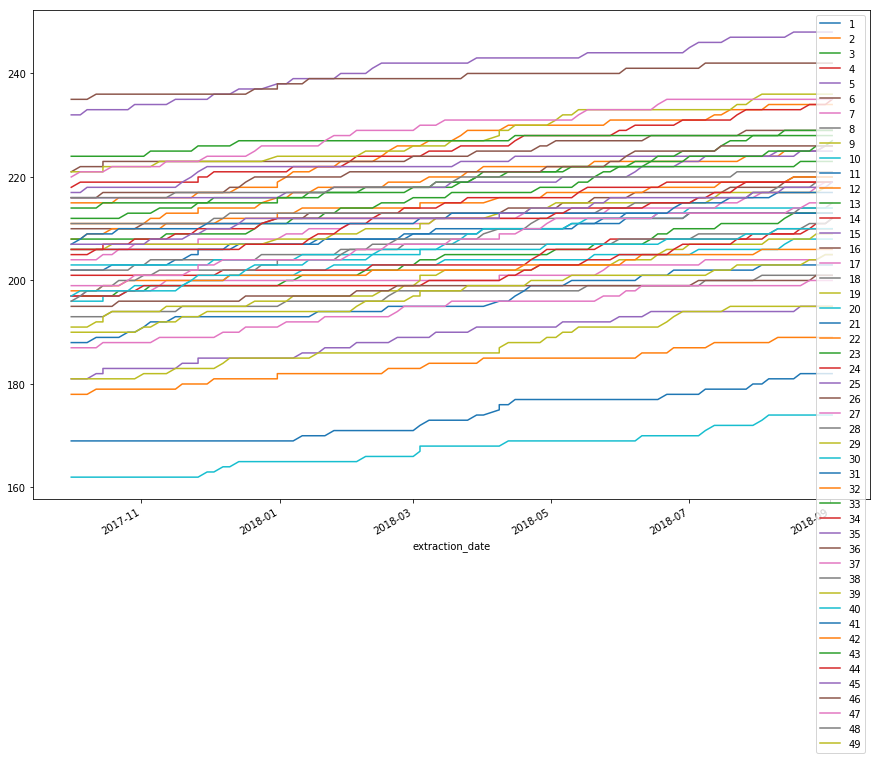

In [24]:
%matplotlib inline

occurrences_df.tail(100).plot(figsize=(15,10))